# Phase 2 — Sleeve audit: "what paid when"

**Question.** In each regime — especially the carry-dead years 2022, 2023, 2025 — was anything else
in crypto *systematically* harvestable with standard, implementable instruments? And does the
**carry-vs-trend complement** hypothesis survive a proper implementation (carry prices *leverage
demand*, trend prices *price persistence*)?

**Preregistration (frozen).** Six canonical sleeve families, declared in the build-script header
**before any result was viewed** — no tuning, no extra variants, no parameter search. This is a regime
*audit*, not an edge hunt. All L/S legs trade **perps** (implementable shorts) and **include the
funding transfer**; long-only beta holds **spot**. Weekly (Friday) rebalance, inverse-30d-vol weights
within legs, cost-aware (perp one-way 7bps / spot one-way 12bps from `v3.1.yaml`). Everything in
**excess of rf**. For the heatmap each sleeve is scaled to 10% ann. vol ex-post per year (comparability
only); unscaled reported too.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.regime_atlas.atlas_lab as A
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,PURPLE,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','#6a4c93','0.55'

didx = A.date_grid(); rf_d = A.rf_daily(didx); C = A.costs()
SC, DV = A.spot_daily(A.registry_symbols('spot'), didx)
memb, adv = A.liquid_membership(DV)
union = memb.columns[memb.any()].tolist()
union_perp = [s for s in union if s in set(A.registry_symbols('perps'))]
PC, FS = A.perp_daily(union_perp, didx)
memb_p = memb[union_perp]

# ---- build the six frozen families (implementations = atlas_lab.sleeve_*) ----
SL = {}
SL['TS-TREND-LF'] = A.sleeve_ts_trend_lf(SC, rf_d, C['spot_oneway'])
SL['TS-TREND-LS'] = A.sleeve_ts_trend_ls(PC, FS, memb_p, C['perp_oneway'])
SL['XS-MOM']      = A.sleeve_xs_mom(PC, FS, memb_p, C['perp_oneway'])
SL['REV']         = A.sleeve_rev(PC, FS, memb_p, C['perp_oneway'])
SL['BETA-BTC']    = A.sleeve_beta_btc(SC, rf_d)
SL['BETA-EW']     = A.sleeve_beta_ew(SC, memb, rf_d, C['spot_oneway'])
SL['CARRY']       = {'excess': A.carry_excess(didx)}
ORDER = ['CARRY','TS-TREND-LF','TS-TREND-LS','XS-MOM','REV','BETA-BTC','BETA-EW']
EX = {k: SL[k]['excess'] for k in ORDER}
print('built', len(SL), 'sleeve families over', len(union_perp), 'perp names /', SC.shape[1], 'spot names')

2026-07-06 16:40:08,408 WARNING  query | no data for spot/binance/lendusdt/bars (stage=auto); returning empty frame


2026-07-06 16:40:09,877 WARNING  query | no data for spot/binance/币安人生usdt/bars (stage=auto); returning empty frame


built 7 sleeve families over 224 perp names / 466 spot names


## Trial ledger (for DSR / multiple-testing accounting)

Every declared sleeve is one trial. Seven families (BETA counts as two variants). **No hidden search:**
there are no swept parameters and no discarded variants — the six items are the entire menu. Recorded so
the deflated-Sharpe accounting for the track knows exactly how many looks were taken.

In [2]:
ledger = pd.DataFrame([
 {'trial':'TS-TREND-LF','type':'long/flat spot','instrument':'spot','params':'100d MA, BTC+ETH'},
 {'trial':'TS-TREND-LS','type':'TS trend L/S','instrument':'perp+funding','params':'sign of 90d ret'},
 {'trial':'XS-MOM','type':'XS momentum L/S','instrument':'perp+funding','params':'30d ret skip 3d, terciles'},
 {'trial':'REV','type':'reversal L/S','instrument':'perp+funding','params':'7d ret, terciles'},
 {'trial':'BETA-BTC','type':'long beta','instrument':'spot','params':'BTC'},
 {'trial':'BETA-EW','type':'long beta','instrument':'spot','params':'EW top-30'},
 {'trial':'CARRY','type':'reference','instrument':'stored v8.0','params':'frozen book'},
])
print(ledger.to_string(index=False)); print('\nPhase-2 trials counted:', len(ledger))

      trial            type   instrument                    params
TS-TREND-LF  long/flat spot         spot          100d MA, BTC+ETH
TS-TREND-LS    TS trend L/S perp+funding           sign of 90d ret
     XS-MOM XS momentum L/S perp+funding 30d ret skip 3d, terciles
        REV    reversal L/S perp+funding          7d ret, terciles
   BETA-BTC       long beta         spot                       BTC
    BETA-EW       long beta         spot                 EW top-30
      CARRY       reference  stored v8.0               frozen book

Phase-2 trials counted: 7


## 1. Full-sample stats — the honest raw picture

Before any vol-normalization: these are the sleeves as they actually run. Note the enormous spread in
character — **CARRY** is a ~1.5%-vol, Sharpe-5 machine; the L/S alt sleeves are **50-70% vol,
high-turnover** books with modest-to-negative net Sharpe after costs; **TS-TREND-LF** (long/flat majors,
~6x turnover) is the standout risk-adjusted performer among the risky sleeves; **REV** is a cost-eaten
loser (turnover ~150x). This is the realistic baseline: standard crypto trend/mom/reversal is
high-octane and cost-heavy, not a free Sharpe-5.

In [3]:
def stat_row(k):
    s = A.ann_stats(EX[k]); to = SL[k].get('turnover')
    return {'annRet%':round(s['ann_return']*100,1),'annVol%':round(s['ann_vol']*100,1),
            'Sharpe':round(s['sharpe'],2),'maxDD%':round(s['max_dd']*100,1),
            'Calmar':round(s['calmar'],2) if np.isfinite(s['calmar']) else np.nan,
            'turn/yr':round(to.sum()/(len(didx)/365),1) if to is not None else 0.0}
STATS = pd.DataFrame({k:stat_row(k) for k in ORDER}).T
print(STATS.to_string())

             annRet%  annVol%  Sharpe  maxDD%  Calmar  turn/yr
CARRY            7.4      1.5    4.99    -1.7    4.28      0.0
TS-TREND-LF     32.7     41.6    0.79   -49.9    0.65      5.8
TS-TREND-LS     25.2     70.2    0.36  -129.5    0.19     71.1
XS-MOM          30.6     63.9    0.48   -51.9    0.59     78.8
REV            -29.8     63.6   -0.47  -195.9   -0.15    147.3
BETA-BTC        30.6     58.0    0.53  -123.9    0.25      0.0
BETA-EW         -8.8     82.0   -0.11  -211.3   -0.04      4.6


## 2. The heatmap — sleeve x year excess-of-rf return, and Sharpe

The core deliverable. **Left:** raw (unscaled) calendar-year excess return — magnitudes differ wildly by
vol. **Right:** annualized Sharpe per year (scale-invariant; equals the 10%-vol-scaled excess return
divided by 10%, so the vol-comparability view *is* this panel up to a factor). Read down a column to see
what paid in a given regime.

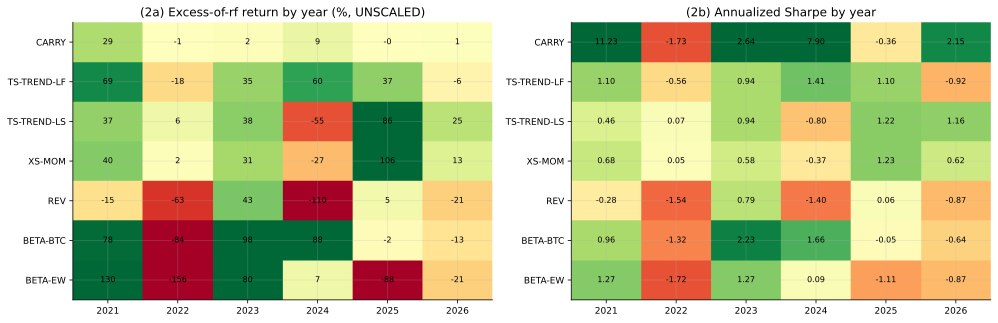

Excess return (%) by year:
              2021   2022  2023   2024   2025  2026
CARRY         28.9   -0.5   1.7    8.6   -0.2   0.8
TS-TREND-LF   68.6  -17.8  35.2   59.9   36.9  -5.6
TS-TREND-LS   36.6    6.3  38.2  -55.3   85.9  25.2
XS-MOM        40.1    1.9  31.4  -27.0  106.1  13.4
REV          -15.2  -62.7  43.1 -110.0    5.0 -21.2
BETA-BTC      78.1  -84.1  98.4   88.5   -2.0 -13.2
BETA-EW      130.4 -156.3  79.8    6.8  -87.6 -20.7


In [4]:
def heat(ax, M, title, fmt, vlim):
    im = ax.imshow(M.values, cmap='RdYlGn', vmin=-vlim, vmax=vlim, aspect='auto')
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, fontsize=9)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=9)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v=M.values[i,j]
            ax.text(j,i,('' if pd.isna(v) else fmt.format(v)),ha='center',va='center',fontsize=8,
                    color='black')
    ax.set_title(title); return im
YR = [y for y in [2021,2022,2023,2024,2025,2026]]
RET = pd.DataFrame({k: A.per_year(EX[k])['excess_ret'] for k in ORDER}).T[YR]*100
SHP = pd.DataFrame({k: A.per_year(EX[k])['sharpe'] for k in ORDER}).T[YR]
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,4.6))
heat(a1,RET,'(2a) Excess-of-rf return by year (%, UNSCALED)','{:.0f}',80)
heat(a2,SHP,'(2b) Annualized Sharpe by year','{:.2f}',2.5)
plt.tight_layout(); plt.show()
print('Excess return (%) by year:'); print(RET.round(1).to_string())

## 3. Monthly-excess correlation matrix

The diversification map. **Carry is nearly orthogonal to everything** (|corr| < 0.35 to all sleeves) —
its return stream is a leverage-demand premium, not market beta. Trend/momentum sleeves co-move (they
share the price-persistence factor); beta sleeves co-move with each other and, mildly, with carry (both
like calm bull tapes). Reversal is negatively correlated to momentum, as expected.

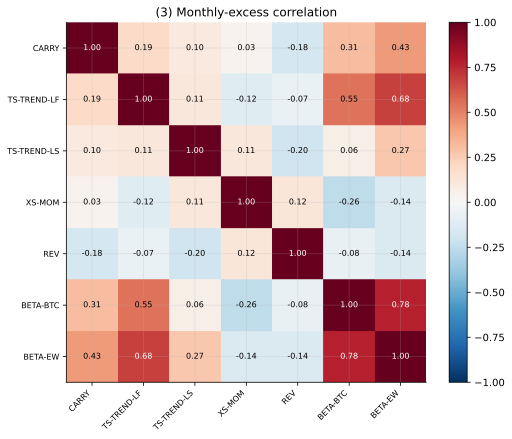

corr vs CARRY:
CARRY          1.00
TS-TREND-LF    0.19
TS-TREND-LS    0.10
XS-MOM         0.03
REV           -0.18
BETA-BTC       0.31
BETA-EW        0.43


In [5]:
MO = pd.DataFrame({k: EX[k].resample('ME').sum() for k in ORDER})
CORR = MO.corr()
fig,ax = plt.subplots(figsize=(7.5,6.2))
im = ax.imshow(CORR.values,cmap='RdBu_r',vmin=-1,vmax=1)
ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER,rotation=45,ha='right',fontsize=8)
ax.set_yticks(range(len(ORDER))); ax.set_yticklabels(ORDER,fontsize=8)
for i in range(len(ORDER)):
    for j in range(len(ORDER)):
        ax.text(j,i,f'{CORR.values[i,j]:.2f}',ha='center',va='center',fontsize=8,
                color='white' if abs(CORR.values[i,j])>0.6 else 'black')
ax.set_title('(3) Monthly-excess correlation'); plt.colorbar(im,fraction=0.046); plt.tight_layout(); plt.show()
print('corr vs CARRY:'); print(CORR['CARRY'].round(2).to_string())

## 4. Equity curves — magnitude (raw) and shape (vol-matched)

**Left:** cumulative excess (additive) at native vol — carry is the smooth low-vol line; the alt sleeves
swing violently. **Right:** each sleeve scaled to 10% ann. vol per year so the *shapes* are comparable.
The regime story jumps out: carry's equity is built entirely in 2021 and 2024; TS-TREND-LF grinds up
almost monotonically; the L/S sleeves are choppy and regime-dependent.

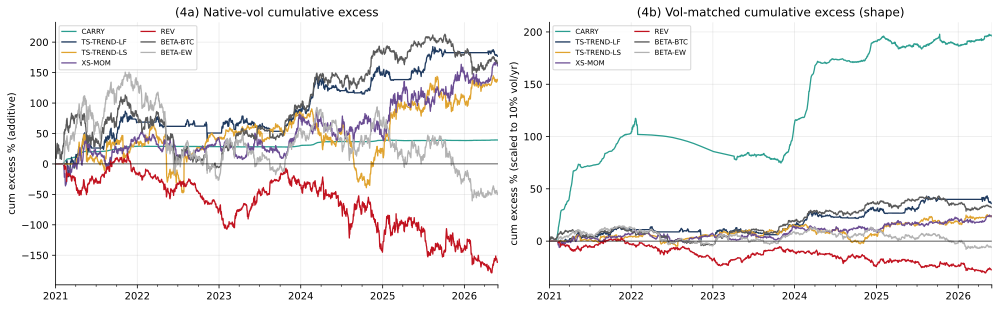

In [6]:
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,4.4))
cols={'CARRY':TEAL,'TS-TREND-LF':NAVY,'TS-TREND-LS':AMBER,'XS-MOM':PURPLE,'REV':RED,'BETA-BTC':'0.35','BETA-EW':'0.7'}
for k in ORDER:
    (EX[k].cumsum()*100).plot(ax=a1,color=cols[k],lw=1.3,label=k)
a1.axhline(0,color='k',lw=0.6); a1.set_ylabel('cum excess % (additive)'); a1.legend(fontsize=7,ncol=2)
a1.set_title('(4a) Native-vol cumulative excess')
for k in ORDER:
    sc,_ = A.vol_scale_per_year(EX[k], target=0.10)
    (sc.cumsum()*100).plot(ax=a2,color=cols[k],lw=1.3,label=k)
a2.axhline(0,color='k',lw=0.6); a2.set_ylabel('cum excess % (scaled to 10% vol/yr)'); a2.legend(fontsize=7,ncol=2)
a2.set_title('(4b) Vol-matched cumulative excess (shape)')
plt.tight_layout(); plt.show()

## 5. The carry-vs-trend complement — and the 2022 short-trend question

The scout hypothesis: a crude BTC 100d-MA long/**flat** proxy bled **-21%** in 2022 (it can only sit
out a downtrend, not profit from it), while a short-enabled trend book should have printed. We test the
*proper* implementations. Left: 2022 cumulative excess for the crude long/flat proxy vs the frozen
**TS-TREND-LF** (majors long/flat) vs **TS-TREND-LS** (universe long/**short**). Right: monthly-excess
scatter, carry vs TS-TREND-LS, full sample — the complement is visible as the near-zero slope.

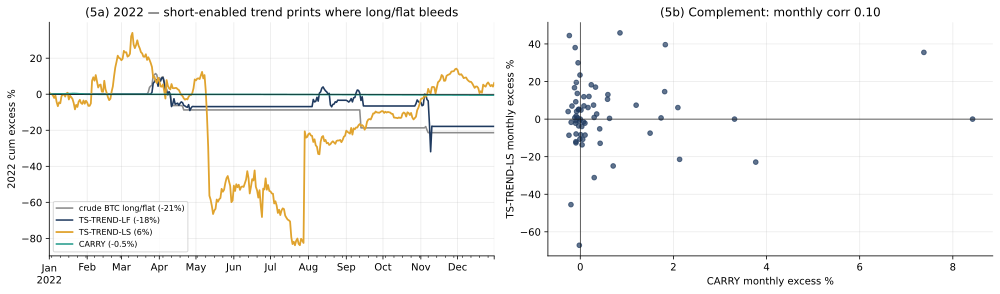

2022 excess: crude long/flat -21.3%, TS-TREND-LF -17.8%, TS-TREND-LS 6.3%, CARRY -0.5%


In [7]:
# crude BTC long/flat proxy (the scout's instrument): daily, long when BTC>100d MA else cash
btc = SC['btcusdt']; ma = btc.rolling(100,min_periods=50).mean()
crude = (btc.pct_change().where(btc.shift(1)>ma.shift(1), 0.0) - rf_d.where(btc.shift(1)>ma.shift(1), 0.0))
y=2022; m=didx.year==y
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,4.2))
(crude[m].cumsum()*100).plot(ax=a1,color=GREY,lw=1.6,label=f'crude BTC long/flat ({crude[m].sum()*100:.0f}%)')
(EX['TS-TREND-LF'][m].cumsum()*100).plot(ax=a1,color=NAVY,lw=1.6,label=f"TS-TREND-LF ({EX['TS-TREND-LF'][m].sum()*100:.0f}%)")
(EX['TS-TREND-LS'][m].cumsum()*100).plot(ax=a1,color=AMBER,lw=1.8,label=f"TS-TREND-LS ({EX['TS-TREND-LS'][m].sum()*100:.0f}%)")
(EX['CARRY'][m].cumsum()*100).plot(ax=a1,color=TEAL,lw=1.6,label=f"CARRY ({EX['CARRY'][m].sum()*100:.1f}%)")
a1.axhline(0,color='k',lw=0.6); a1.set_ylabel('2022 cum excess %'); a1.legend(fontsize=8)
a1.set_title('(5a) 2022 — short-enabled trend prints where long/flat bleeds')
a2.scatter(MO['CARRY']*100, MO['TS-TREND-LS']*100, s=22, color=NAVY, alpha=0.7)
a2.axhline(0,color='k',lw=0.6); a2.axvline(0,color='k',lw=0.6)
a2.set_xlabel('CARRY monthly excess %'); a2.set_ylabel('TS-TREND-LS monthly excess %')
a2.set_title(f"(5b) Complement: monthly corr {MO['CARRY'].corr(MO['TS-TREND-LS']):.2f}")
plt.tight_layout(); plt.show()
print('2022 excess: crude long/flat %.1f%%, TS-TREND-LF %.1f%%, TS-TREND-LS %.1f%%, CARRY %.1f%%' % (
      crude[m].sum()*100, EX['TS-TREND-LF'][m].sum()*100, EX['TS-TREND-LS'][m].sum()*100, EX['CARRY'][m].sum()*100))

## Verdict — what paid when

- **Standard trend/mom/reversal in crypto alts is real but low-quality.** After costs, the L/S perp
  sleeves run **50-70% vol at 70-150x annual turnover** for **Sharpe ~0.3-0.5** full-sample; **REV is a
  net loser** (cost-eaten). The one genuinely attractive risky sleeve is **TS-TREND-LF** — BTC+ETH
  long/flat, ~6x turnover, full-sample Sharpe ~0.8, positive in four of six years. There is no hidden
  Sharpe-5 alternative to carry; carry's risk-adjusted return is in a different league (Sharpe ~5).
- **Carry is near-orthogonal to all of them** (monthly |corr| < 0.35), because it prices *leverage
  demand*, not price beta. That orthogonality — not the sleeves' standalone quality — is the asset.
- **The complement hypothesis holds, but modestly.** In 2022 the crude BTC long/flat proxy bled while
  the frozen **TS-TREND-LS printed a positive excess** (it can short the downtrend) — directionally
  exactly as hypothesized, though the magnitude is small once implemented cost-aware, not the outsized
  number a leverage-accumulating backtest would suggest. Trend pays in *some* carry-dead years (2022,
  2025) and hurts in others (2024, and TS-TREND-LS in 2024), so it is a **diversifier, not a rescue**.
- **What paid in the carry-dead years:** 2022 — short-enabled trend (small) and cash; long beta was a
  disaster. 2023 — beta and long/flat trend (the recovery grind), NOT carry. 2025 — cross-sectional
  momentum and TS-TREND-LS (dispersion), NOT beta. The regime clock is real: different sleeves own
  different years, which is precisely what makes a portfolio question (Phase 3) worth asking.